In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("../data/preprocessed_tuberculosis_data.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 988 entries, 0 to 987
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   two_weeks_fever              988 non-null    int64
 1   coughing_blood               988 non-null    int64
 2   sputum_mixed_with_blood      988 non-null    int64
 3   night_sweats                 988 non-null    int64
 4   chest_pain                   988 non-null    int64
 5   back_pain                    988 non-null    int64
 6   breath_shortness             988 non-null    int64
 7   weight_loss                  988 non-null    int64
 8   body_feels_tired             988 non-null    int64
 9   lumps                        988 non-null    int64
 10  continuous_cough_and_phlegm  988 non-null    int64
 11  swollen_lymph_nodes          988 non-null    int64
 12  loss_of_appetite             988 non-null    int64
 13  tuberculosis                 988 non-null    int64
dtypes: in

## Univariate Analysis

### Target Column

Text(0.5, 1.0, 'Distribution of Target')

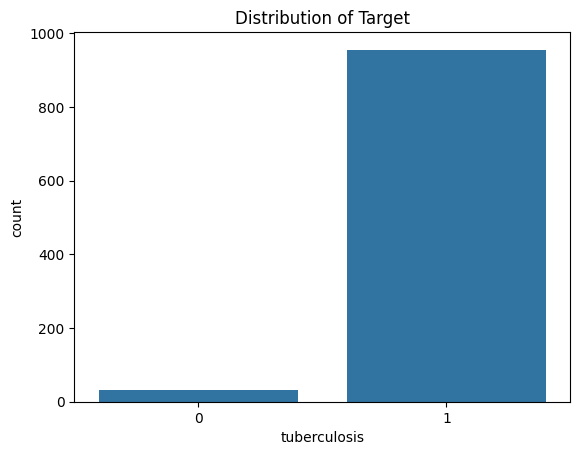

In [5]:
sns.barplot(df['tuberculosis'].value_counts())
plt.title("Distribution of Target")

In [6]:
df['tuberculosis'].value_counts(normalize =True)  

tuberculosis
1    0.966599
0    0.033401
Name: proportion, dtype: float64

Text(0.5, 1.0, 'Proportion of people with Tuberculosis')

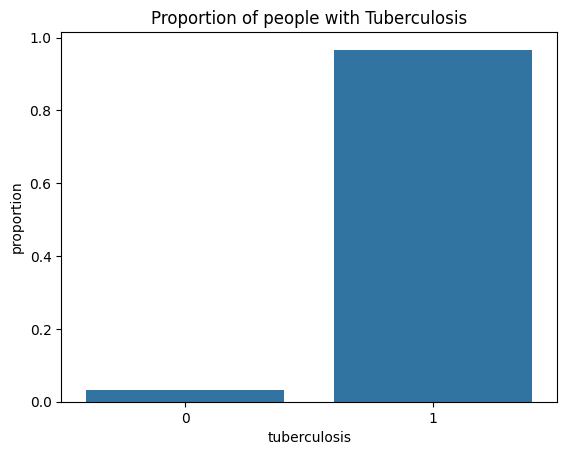

In [7]:
sns.barplot(df['tuberculosis'].value_counts(normalize =True))
plt.title("Proportion of people with Tuberculosis")

### categorical columns 

In [8]:
### since all feature are categorical columns
cat_cols = df.drop(columns='tuberculosis' ).columns.to_list()
cat_cols

['two_weeks_fever',
 'coughing_blood',
 'sputum_mixed_with_blood',
 'night_sweats',
 'chest_pain',
 'back_pain',
 'breath_shortness',
 'weight_loss',
 'body_feels_tired',
 'lumps',
 'continuous_cough_and_phlegm',
 'swollen_lymph_nodes',
 'loss_of_appetite']

Two_Weeks_Fever
two_weeks_fever
0    495
1    493
Name: count, dtype: int64


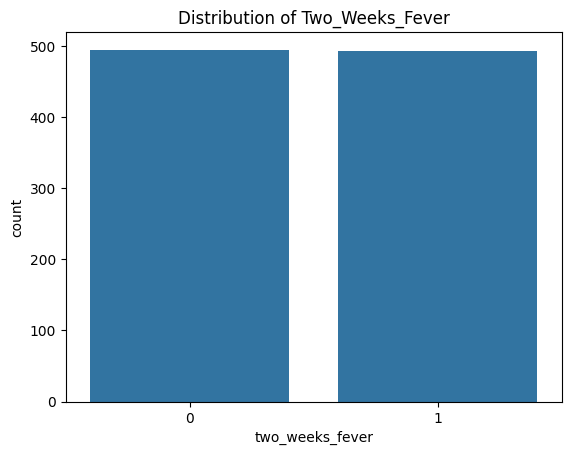

Coughing_Blood
coughing_blood
0    540
1    448
Name: count, dtype: int64


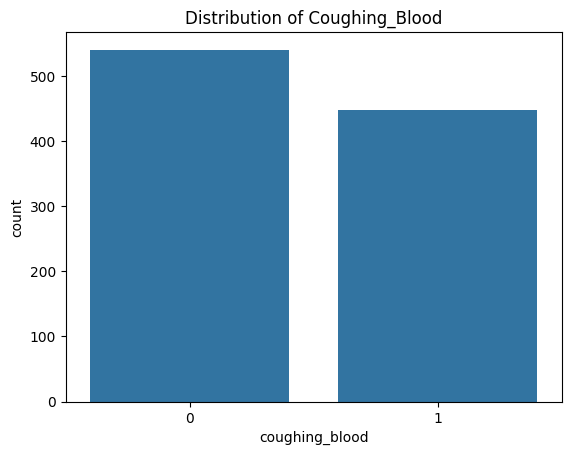

Sputum_Mixed_With_Blood
sputum_mixed_with_blood
1    495
0    493
Name: count, dtype: int64


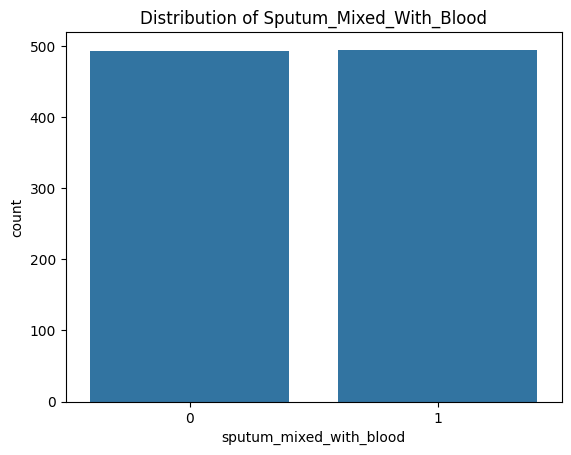

Night_Sweats
night_sweats
1    510
0    478
Name: count, dtype: int64


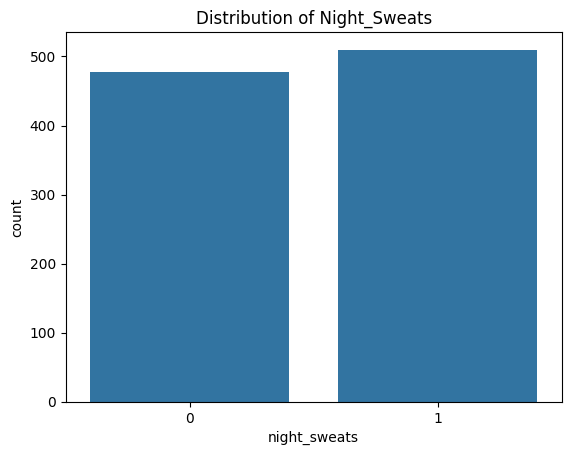

Chest_Pain
chest_pain
0    509
1    479
Name: count, dtype: int64


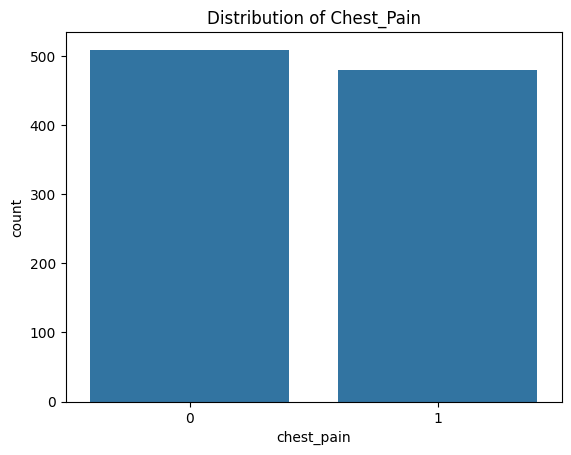

Back_Pain
back_pain
1    507
0    481
Name: count, dtype: int64


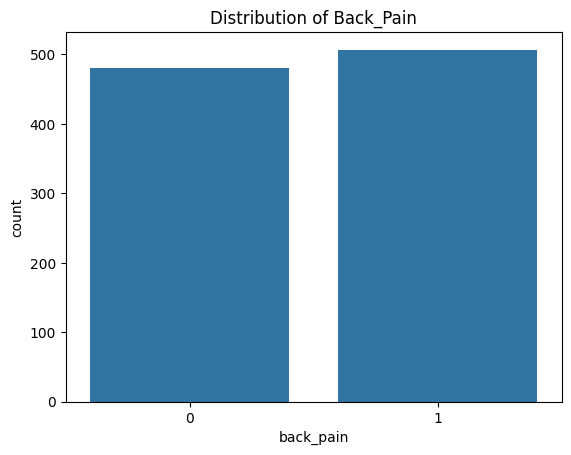

Breath_Shortness
breath_shortness
0    506
1    482
Name: count, dtype: int64


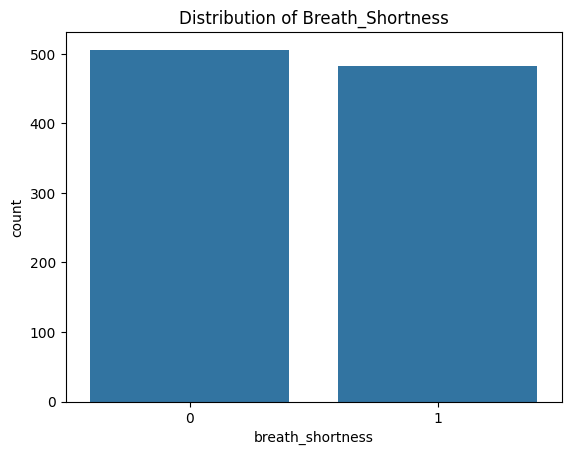

Weight_Loss
weight_loss
1    502
0    486
Name: count, dtype: int64


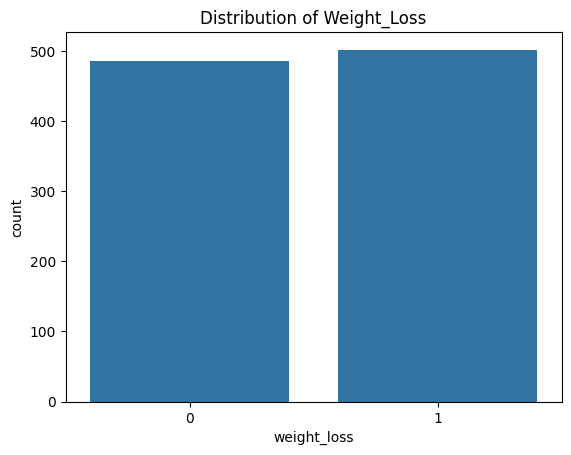

Body_Feels_Tired
body_feels_tired
0    495
1    493
Name: count, dtype: int64


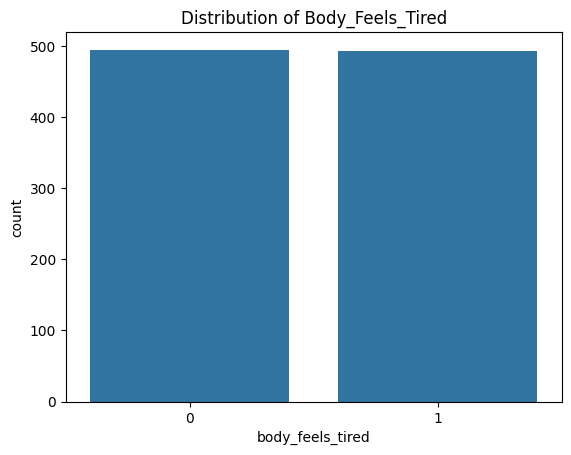

Lumps
lumps
0    525
1    463
Name: count, dtype: int64


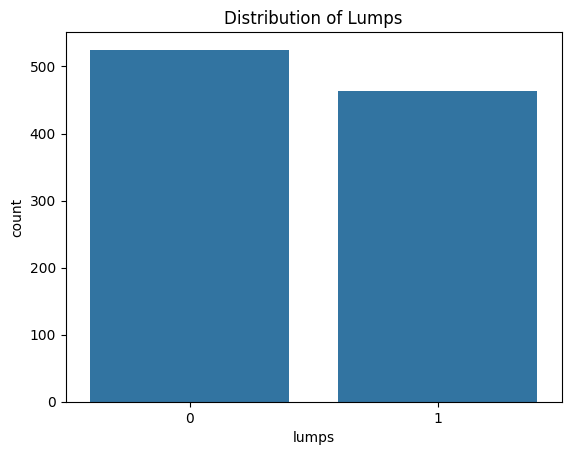

Continuous_Cough_And_Phlegm
continuous_cough_and_phlegm
0    514
1    474
Name: count, dtype: int64


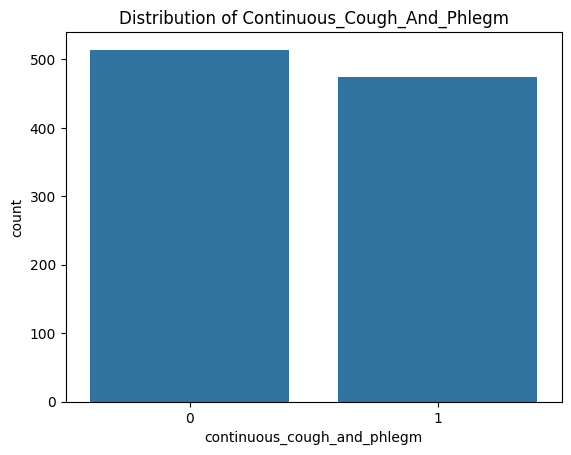

Swollen_Lymph_Nodes
swollen_lymph_nodes
0    527
1    461
Name: count, dtype: int64


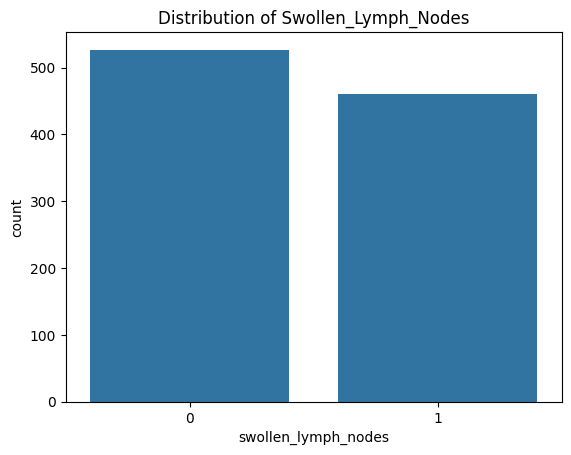

Loss_Of_Appetite
loss_of_appetite
0    517
1    471
Name: count, dtype: int64


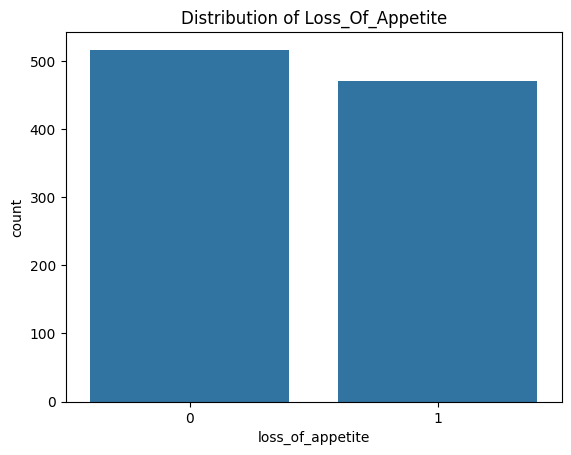

In [9]:
for cols in cat_cols:
    cat_count  = df[cols].value_counts()
    print(f'{cols.title()}')
    print("=======================")
    print(cat_count)

    sns.barplot(cat_count)
    plt.title(f'Distribution of {cols.title()}')
    plt.show()

### Bivariate Analysis

#### Exploring target by categories

two_weeks_fever
0    0.945455
1    0.987830
Name: tuberculosis, dtype: float64


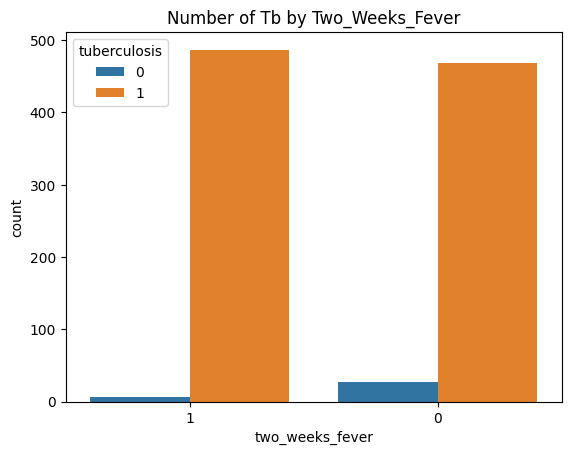

coughing_blood
0    0.944444
1    0.993304
Name: tuberculosis, dtype: float64


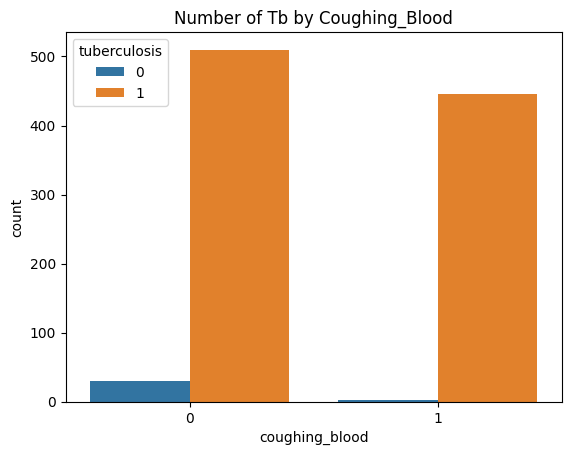

sputum_mixed_with_blood
0    0.943205
1    0.989899
Name: tuberculosis, dtype: float64


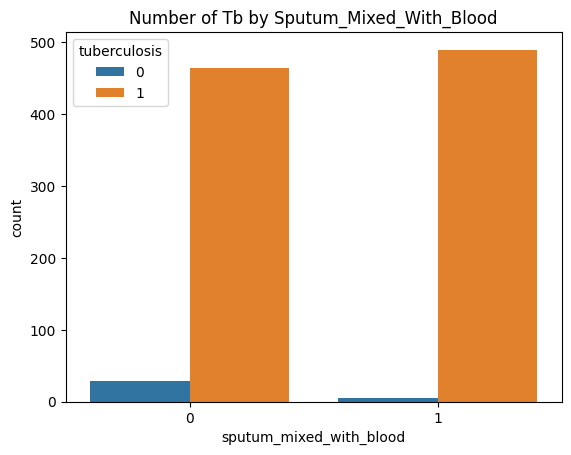

night_sweats
0    0.958159
1    0.974510
Name: tuberculosis, dtype: float64


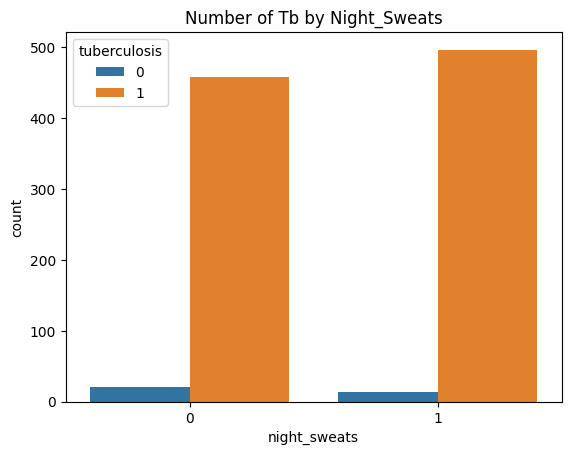

chest_pain
0    0.952849
1    0.981211
Name: tuberculosis, dtype: float64


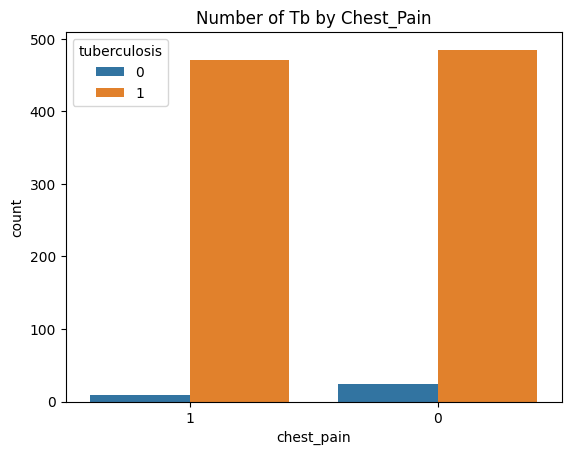

back_pain
0    0.966736
1    0.966469
Name: tuberculosis, dtype: float64


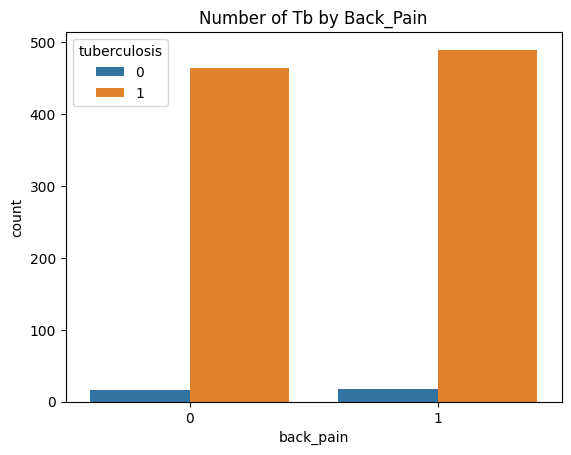

breath_shortness
0    0.958498
1    0.975104
Name: tuberculosis, dtype: float64


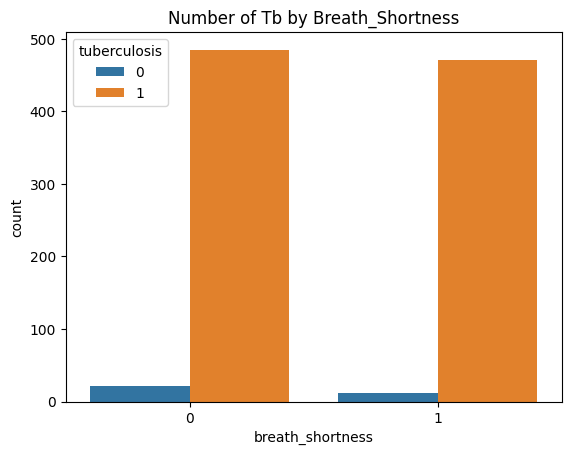

weight_loss
0    0.948560
1    0.984064
Name: tuberculosis, dtype: float64


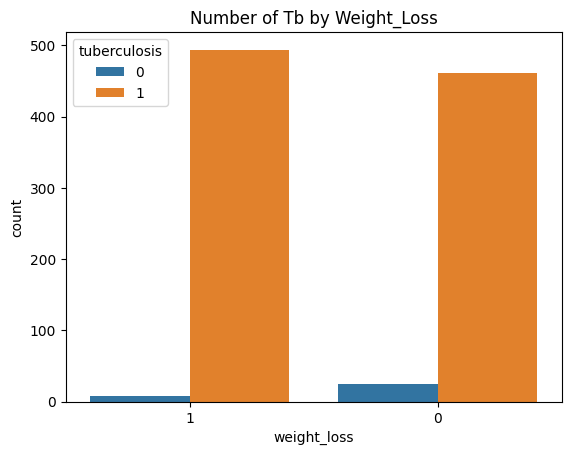

body_feels_tired
0    0.975758
1    0.957404
Name: tuberculosis, dtype: float64


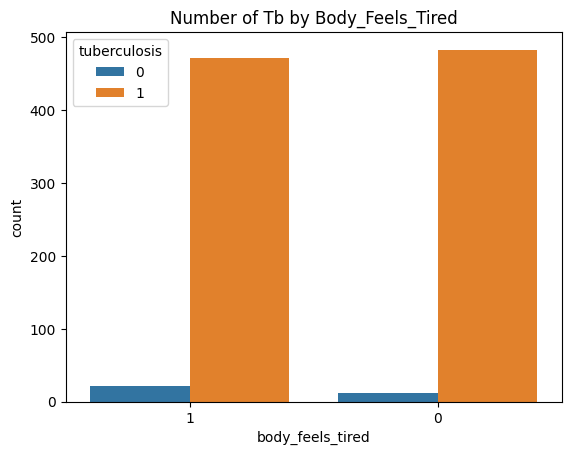

lumps
0    0.948571
1    0.987041
Name: tuberculosis, dtype: float64


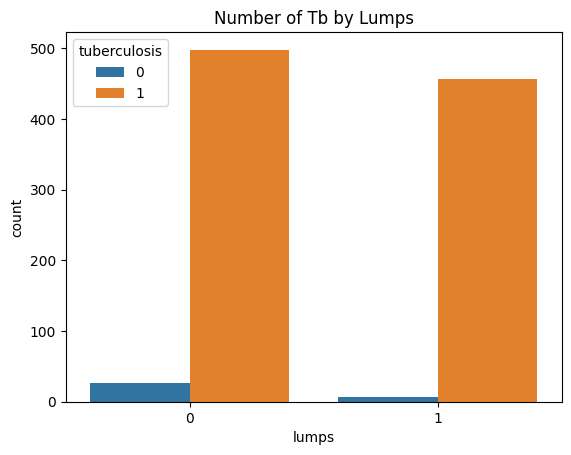

continuous_cough_and_phlegm
0    0.943580
1    0.991561
Name: tuberculosis, dtype: float64


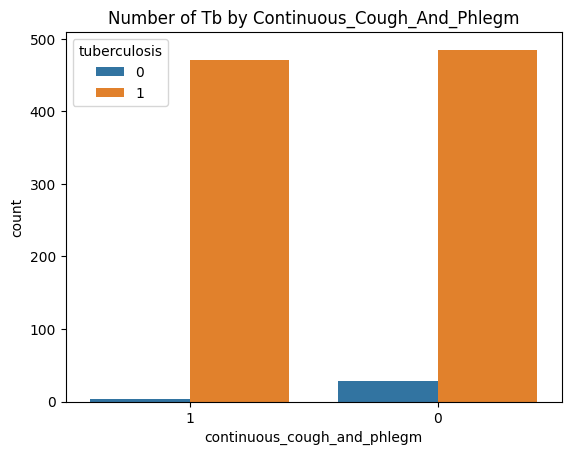

swollen_lymph_nodes
0    0.946869
1    0.989154
Name: tuberculosis, dtype: float64


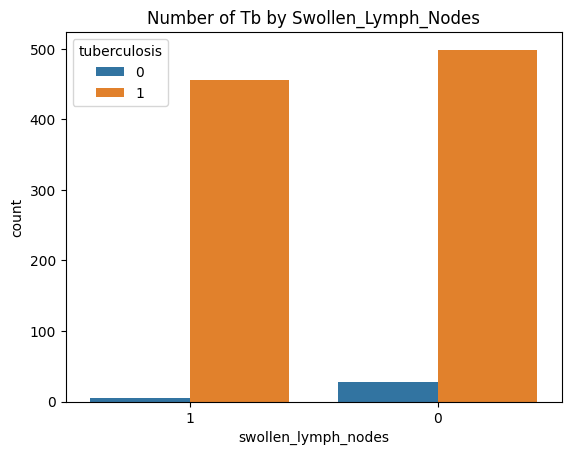

loss_of_appetite
0    0.947776
1    0.987261
Name: tuberculosis, dtype: float64


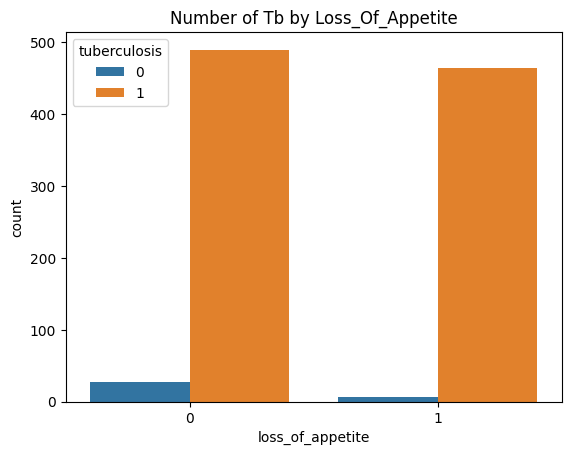

In [10]:
for col in cat_cols:
    group_tb_rate = df.groupby(col)['tuberculosis'].mean()
    print(group_tb_rate)
    sns.countplot(x=df[col].astype(str), hue=df['tuberculosis'])
    plt.title(f'Number of Tb by {col.title()}')
    plt.show()

### Check mutual information score between features and target

In [11]:
from sklearn.metrics import mutual_info_score

In [12]:
df[cat_cols].apply(
    lambda feature: mutual_info_score(df['tuberculosis'] ,  feature)
).sort_values(ascending = False)

coughing_blood                 1.087551e-02
continuous_cough_and_phlegm    1.011511e-02
sputum_mixed_with_blood        9.274556e-03
swollen_lymph_nodes            7.692629e-03
two_weeks_fever                7.504305e-03
loss_of_appetite               6.562029e-03
lumps                          6.235842e-03
weight_loss                    5.098427e-03
chest_pain                     3.238553e-03
body_feels_tired               1.320128e-03
breath_shortness               1.082224e-03
night_sweats                   1.038808e-03
back_pain                      2.748887e-07
dtype: float64

## Key Takeaway

* this dataset contains records for 988 patient
* Approxiamately 96% is tuberculosis positive while 3% is negative

